In [4]:
import os

print(os.getcwd())
print(os.listdir())

/Users/sanikadhide/Desktop/ML ASSIGNMENTS
['ML 2.ipynb', 'uber.csv', 'ML 3.ipynb', 'wine (1).csv', 'ML 1.ipynb', '.ipynb_checkpoints']


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


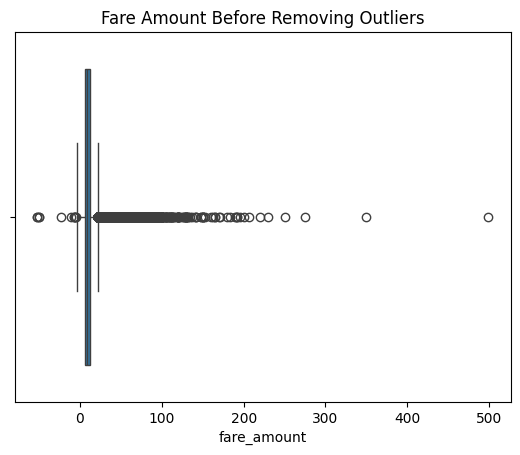

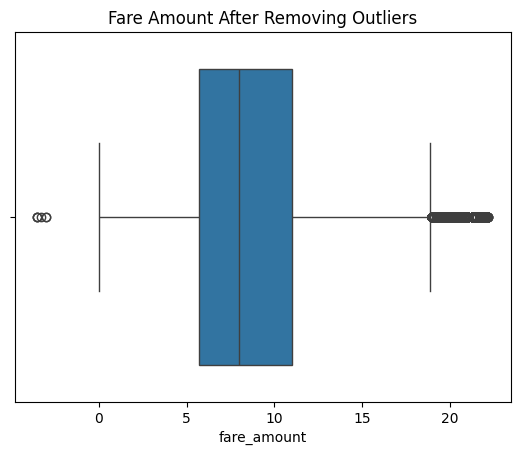

                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000367         0.002618   
pickup_longitude      0.000367          1.000000        -0.812047   
pickup_latitude       0.002618         -0.812047         1.000000   
dropoff_longitude    -0.002413          0.835950        -0.767103   
dropoff_latitude      0.000589         -0.850574         0.684558   
passenger_count       0.012618         -0.000751        -0.001604   

                   dropoff_longitude  dropoff_latitude  passenger_count  
fare_amount                -0.002413          0.000589         0.012618  
pickup_longitude            0.835950         -0.850574        -0.000751  
pickup_latitude            -0.767103          0.684558        -0.001604  
dropoff_longitude           1.000000         -0.913949         0.000203  
dropoff_latitude           -0.913949          1.000000        -0.000853  
passenger_count             0.000203         -0.000853         1.000000 

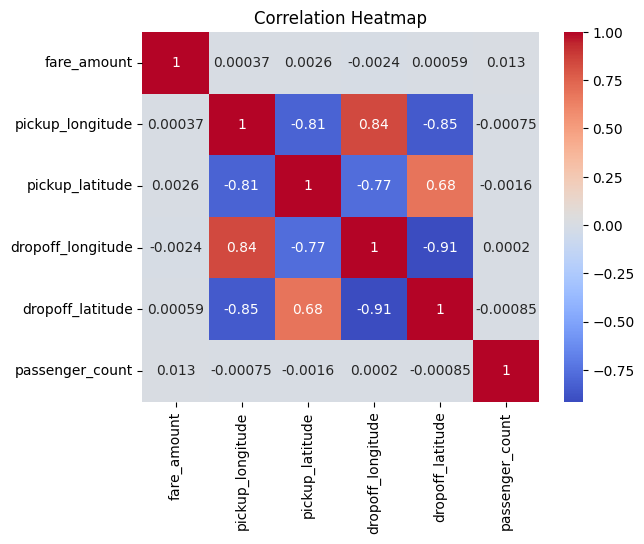

Linear Regression - R2 Score: 0.0002, RMSE: 4.16
Ridge Regression - R2 Score: 0.0002, RMSE: 4.16
Lasso Regression - R2 Score: -0.0000, RMSE: 4.16


In [5]:
# Importing required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Importing machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Load the dataset
df = pd.read_csv('uber.csv', on_bad_lines='skip')
df.head()

"""Understanding the dataset"""
df.isnull().sum()
df.shape
df.info()
df.columns

"""Data Cleaning"""
# Convert data types
df['pickup_latitude'] = pd.to_numeric(df['pickup_latitude'], errors='coerce')
df['fare_amount'] = pd.to_numeric(df['fare_amount'], errors='coerce')
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], errors='coerce')

# Remove unnecessary columns
df = df.drop(columns=['Unnamed: 0', 'key', 'pickup_datetime'])

# Fill missing values
columns = ['dropoff_longitude', 'dropoff_latitude']
for column in columns:
    df[column] = df[column].fillna(df[column].mean())

df = df.dropna()

"""Handling outliers"""
# Boxplot before removing outliers
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount Before Removing Outliers")
plt.show()

# Calculate IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Remove outliers
df_no_outliers = df[
    (df["fare_amount"] >= lower_bound) &
    (df["fare_amount"] <= upper_bound)
]

# Boxplot after removing outliers
sns.boxplot(x=df_no_outliers["fare_amount"])
plt.title("Fare Amount After Removing Outliers")
plt.show()

"""Correlation"""
# Check correlation
correlation = df_no_outliers.corr(numeric_only=True)
print(correlation)

# Correlation heatmap
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

"""Linear Regression and Regularization Models"""

# Features and target
X = df_no_outliers.drop('fare_amount', axis=1)
y = df_no_outliers['fare_amount']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred = linear_model.predict(X_test)

# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)

# Lasso Regression
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)
y_pred_lasso = lasso_model.predict(X_test)

"""Evaluation metrics"""

def model_evaluation(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{model_name} - R2 Score: {r2:.4f}, RMSE: {rmse:.2f}")

# Evaluate models
model_evaluation(y_test, y_pred, "Linear Regression")
model_evaluation(y_test, y_pred_ridge, "Ridge Regression")
model_evaluation(y_test, y_pred_lasso, "Lasso Regression")